# 05 · La réponse à l'intensité promotionnelle par Double ML (et pourquoi ce n'est pas une élasticité-prix)

Le cahier des charges demande une courbe d'élasticité-prix par famille. Favorita n'a **aucun prix** :
`onpromotion` compte des articles promus, pas une remise. Ce que les données identifient, c'est la réponse des
ventes à l'**intensité** de la promotion (le compte, ramené à l'échelle de la famille), sous contrôles. C'est
utile pour le calendrier (quelles familles répondent), et c'est dit tel quel.

L'outil est le Double ML en modèle partiellement linéaire : `log1p(ventes) = θ · intensité + g(contrôles) + ε`.
On retire des deux côtés ce que les contrôles expliquent (gradient boosting, ajusté en validation croisée par
**blocs de mois**, parce que les lignes d'une même série sont dépendantes), puis on régresse résidu sur résidu.
Les chiffres viennent de `nr dml` (`data/results/dml.json`).

In [1]:
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from novaretail import viz
from novaretail.data import RESULTS
from novaretail.dml import build_table, controls, residualise
from novaretail.features import promo_intensity
from novaretail.workspace import load_world

viz.setup()
export = viz.exporter("../figures")
rep = json.loads((RESULTS / "dml.json").read_text())
fam = pd.read_parquet(RESULTS / "dml_by_family.parquet")
dose = pd.read_parquet(RESULTS / "dml_dose.parquet")
est = pd.read_parquet(RESULTS / "estimates.parquet")
print({k: rep[k] for k in ("rows", "holdout_split", "seconds")})

{'rows': 120000, 'holdout_split': '2015-12-31', 'seconds': 63}


## 1. L'intensité : un proxy de la part d'articles promus

**Attention.** Le nombre d'articles d'une famille n'est pas dans les données. L'intensité est le compte divisé
par le quantile 95 % des comptes positifs de la famille (toutes magasins confondus, l'assortiment d'une famille
étant le même partout). Un jour à intensité 1 est un jour « aussi promu que les 5 % les plus promus de la
famille ». C'est une échelle relative, et θ se lit en log-ventes par unité de cette échelle.

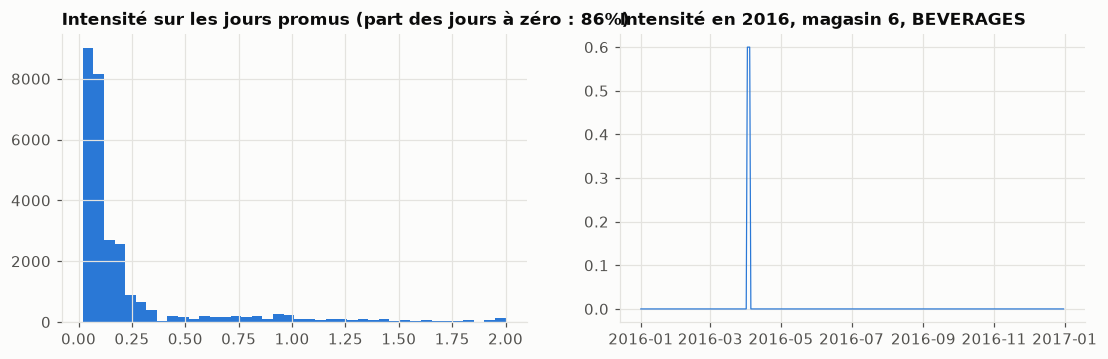

In [2]:
w = load_world()
inten = promo_intensity(w.wide_promo)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.4))
ax = axes[0]
vals = inten.values.ravel()
ax.hist(vals[vals > 0], bins=40, color=viz.BLUE)
ax.set_title("Intensité sur les jours promus (part des jours à zéro : "
             f"{(vals == 0).mean():.0%})")
ax = axes[1]
unit = w.units[len(w.units) // 2]
ax.plot(inten[unit].loc["2016"], color=viz.BLUE, linewidth=0.8)
ax.set_title(f"Intensité en 2016, magasin {unit[0]}, {unit[1]}")
export(fig, "nb05_intensity")
plt.show()

## 2. Le partialling-out, vu

**Intuition.** Après avoir retiré ce que le calendrier, les identités et les retards de la série expliquent,
il reste deux résidus par ligne : celui des ventes et celui de l'intensité. La pente du nuage résidu-sur-résidu
est θ. La validation croisée empêche le modèle de nuisance de « voir » la ligne qu'il corrige.

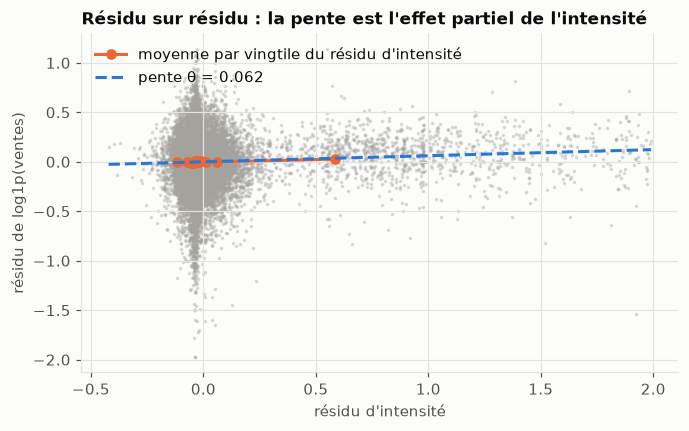

In [3]:
table = build_table(w.panel, w.calendars, inten)
sample = table.sample(min(40_000, len(table)), random_state=0).reset_index(drop=True)
x = controls(sample)
ry, rd = residualise(sample, "y", ["intensity"], x, n_folds=3)
rd = rd[:, 0]
bins = pd.qcut(rd, 20, duplicates="drop")
binned = pd.DataFrame({"rd": rd, "ry": ry}).groupby(bins, observed=True).mean()
fig, ax = plt.subplots(figsize=(7, 4))
ax.scatter(rd, ry, s=2, color=viz.MUTED, alpha=0.3)
ax.plot(binned["rd"], binned["ry"], marker="o", color=viz.ORANGE, label="moyenne par vingtile du résidu d'intensité")
th = rep["pooled_with_lags"]["theta"]["intensity"]
xs = np.linspace(rd.min(), rd.max(), 10)
ax.plot(xs, th * xs, color=viz.BLUE, linestyle="--", label=f"pente θ = {th:.3f}")
ax.set_xlabel("résidu d'intensité")
ax.set_ylabel("résidu de log1p(ventes)")
ax.set_title("Résidu sur résidu : la pente est l'effet partiel de l'intensité")
ax.legend(loc="upper left")
export(fig, "nb05_partialling_out")
plt.show()

## 3. θ global : avec et sans retards, sur l'année tenue à l'écart, et avec DoubleML

**Attention.** Les retards de la série (7, 14, 28 jours) sont un choix : ils absorbent le niveau lent que les
arbres sur identités ajustent mal, mais ils peuvent absorber une partie de l'effet d'une promotion persistante.
Les deux spécifications sont rapportées. Le holdout sur la dernière année dit si la réponse est stable dans le
temps ; DoubleML (la bibliothèque de référence) confirme que le calcul maison n'a pas d'erreur.

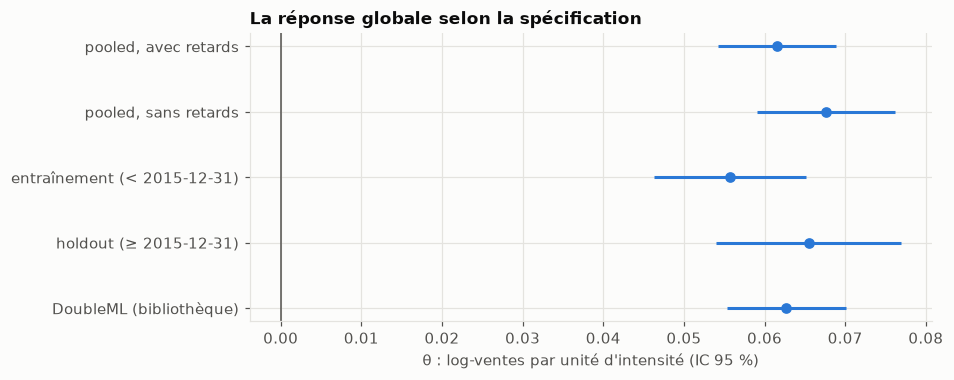

                              theta      se
spec                                       
pooled, avec retards         0.0616  0.0037
pooled, sans retards         0.0676  0.0043
entraînement (< 2015-12-31)  0.0557  0.0048
holdout (≥ 2015-12-31)       0.0655  0.0058
DoubleML (bibliothèque)      0.0627  0.0038


In [4]:
rows = [("pooled, avec retards", rep["pooled_with_lags"]["theta"]["intensity"], rep["pooled_with_lags"]["se"]["intensity"]),
        ("pooled, sans retards", rep["pooled_without_lags"]["theta"]["intensity"], rep["pooled_without_lags"]["se"]["intensity"]),
        (f"entraînement (< {rep['holdout_split']})", rep["holdout"]["train"]["theta"], rep["holdout"]["train"]["se"]),
        (f"holdout (≥ {rep['holdout_split']})", rep["holdout"]["holdout"]["theta"], rep["holdout"]["holdout"]["se"])]
if isinstance(rep.get("doubleml"), dict):
    rows.append(("DoubleML (bibliothèque)", rep["doubleml"]["theta"], rep["doubleml"]["se"]))
cmp = pd.DataFrame(rows, columns=["spec", "theta", "se"]).set_index("spec")
fig, ax = plt.subplots(figsize=(8, 3.4))
ypos = np.arange(len(cmp))
ax.hlines(ypos, cmp["theta"] - 1.96 * cmp["se"], cmp["theta"] + 1.96 * cmp["se"], color=viz.BLUE, linewidth=2)
ax.scatter(cmp["theta"], ypos, color=viz.BLUE, zorder=3)
ax.axvline(0, color=viz.TEXT_2, linewidth=1)
ax.set_yticks(ypos, cmp.index)
ax.invert_yaxis()
ax.set_xlabel("θ : log-ventes par unité d'intensité (IC 95 %)")
ax.set_title("La réponse globale selon la spécification")
export(fig, "nb05_theta_specs")
plt.show()
print(cmp.round(4).to_string())

## 4. Par famille : qui répond

**Exemple.** θ par famille, magasins regroupés. C'est la « courbe » que le calendrier utilise, avec deux
garde-fous : l'intervalle, et la part de jours promus (une famille promue en permanence n'a presque pas de
contraste, son θ est fragile).

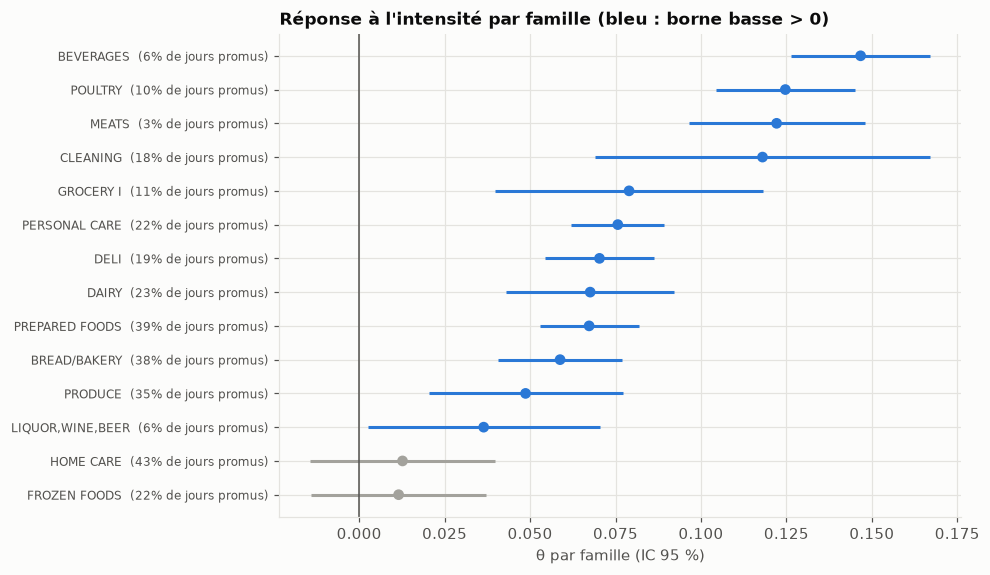

In [5]:
f = fam.sort_values("theta")
fig, ax = plt.subplots(figsize=(8, 0.3 * len(f) + 1.5))
ypos = np.arange(len(f))
colors = [viz.CRITICAL if lo > 0 else viz.MUTED for lo in f["lower"]]
colors = [viz.BLUE if (lo > 0) else viz.MUTED for lo in f["lower"]]
ax.hlines(ypos, f["lower"], f["upper"], color=colors, linewidth=2)
ax.scatter(f["theta"], ypos, c=colors, zorder=3)
ax.axvline(0, color=viz.TEXT_2, linewidth=1)
ax.set_yticks(ypos, [f"{i}  ({p:.0%} de jours promus)" for i, p in zip(f.index, f["share_promoted_days"], strict=True)],
              fontsize=8)
ax.set_xlabel("θ par famille (IC 95 %)")
ax.set_title("Réponse à l'intensité par famille (bleu : borne basse > 0)")
export(fig, "nb05_by_family")
plt.show()

## 5. Dose-réponse par paliers

**Intuition.** Le modèle linéaire impose une réponse proportionnelle. En remplaçant l'intensité par des
indicatrices de paliers (contre les jours sans promotion), on lit la forme : une réponse concave dit que les
derniers articles promus rapportent moins que les premiers.

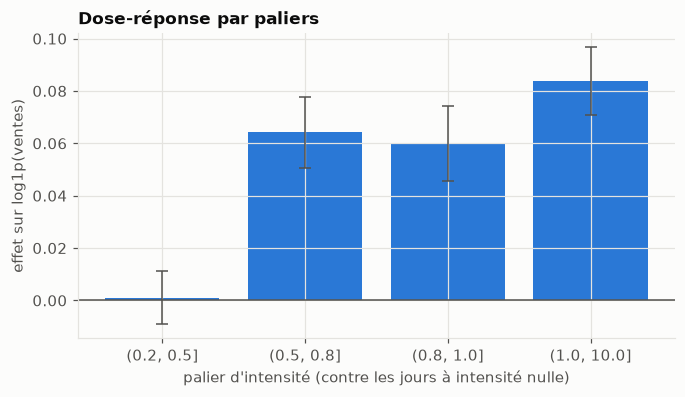

              theta      se   lower   upper  n_rows
(0.2, 0.5]   0.0011  0.0052 -0.0091  0.0112  2177.0
(0.5, 0.8]   0.0642  0.0069  0.0506  0.0778   897.0
(0.8, 1.0]   0.0599  0.0073  0.0456  0.0741   765.0
(1.0, 10.0]  0.0837  0.0066  0.0707  0.0967  1187.0


In [6]:
fig, ax = plt.subplots(figsize=(7, 3.6))
xpos = np.arange(len(dose))
ax.bar(xpos, dose["theta"], color=viz.BLUE, yerr=1.96 * dose["se"], capsize=4,
       error_kw={"ecolor": viz.TEXT_2, "elinewidth": 1})
ax.axhline(0, color=viz.TEXT_2, linewidth=1)
ax.set_xticks(xpos, dose.index)
ax.set_xlabel("palier d'intensité (contre les jours à intensité nulle)")
ax.set_ylabel("effet sur log1p(ventes)")
ax.set_title("Dose-réponse par paliers")
export(fig, "nb05_dose_response")
plt.show()
print(dose.round(4).to_string())

## 6. Concordance avec les campagnes mesurées

**Attention.** Deux mesures du même phénomène avec deux designs : le contrefactuel par campagne (notebook 03)
et le DML sur tout le panel. Pour chaque campagne mesurable, θ de sa famille multiplié par l'intensité moyenne
de la campagne prédit un lift en log ; on le compare au lift mesuré pendant la campagne. Une concordance
grossière suffit ; un désaccord systématique signalerait que l'un des deux designs lit autre chose.

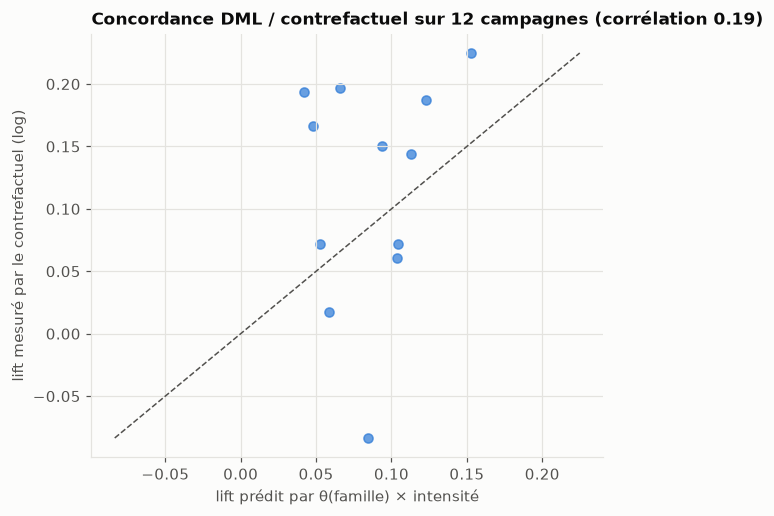

In [7]:
meas = est[est["status"] == "measurable"].copy()
scale = inten.max() / w.wide_promo.max().replace(0, np.nan)
meas["intensity"] = [float(min(2.0, r.mean_count * scale.get((r.store_nbr, r.family), np.nan)))
                     if pd.notna(scale.get((r.store_nbr, r.family), np.nan)) else np.nan for r in meas.itertuples()]
meas = meas.join(fam["theta"], on="family")
meas["predicted_log"] = meas["theta"] * meas["intensity"]
meas["measured_log"] = np.log1p(meas["during_rel"])
ok = meas.dropna(subset=["predicted_log", "measured_log"])
fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(ok["predicted_log"], ok["measured_log"], color=viz.BLUE, alpha=0.7)
lim = [min(ok["predicted_log"].min(), ok["measured_log"].min(), 0), max(ok["predicted_log"].max(), ok["measured_log"].max())]
ax.plot(lim, lim, color=viz.TEXT_2, linestyle="--", linewidth=1)
ax.set_xlabel("lift prédit par θ(famille) × intensité")
ax.set_ylabel("lift mesuré par le contrefactuel (log)")
ax.set_title(f"Concordance DML / contrefactuel sur {len(ok)} campagnes (corrélation "
             f"{ok[['predicted_log', 'measured_log']].corr().iloc[0, 1]:.2f})")
export(fig, "nb05_concordance")
plt.show()

## À retenir

- Pas de prix dans Favorita : la sortie est une **réponse à l'intensité promotionnelle**, pas une élasticité-prix.
- Le DML donne un θ avec une erreur standard valide sous l'hypothèse « intensité comme aléatoire sachant les
  contrôles » ; la validation croisée par blocs de mois respecte la dépendance temporelle.
- Les retards de la série sont un choix à montrer ; le holdout et DoubleML sont des contrôles de stabilité et
  d'implémentation, pas des preuves causales.
- La concordance avec les campagnes mesurées est le seul lien entre les deux designs ; elle est grossière.